# Targets, scores and exact reference draws

Separate a density known up to a constant from an exact reference sampler. The original perturbed Gaussian has a Gaussian envelope because cosine plus sine never exceeds two.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

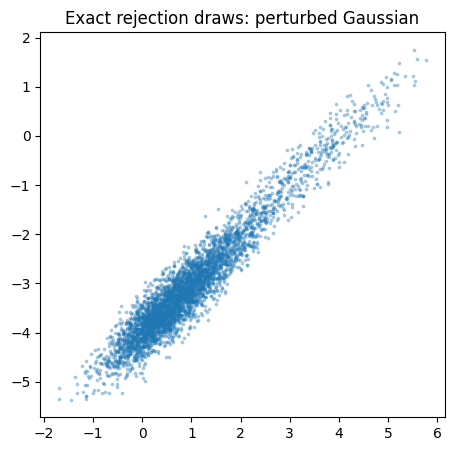

In [2]:
target=load_target("perturbed")
x=np.array([.4,-.3]);z=torch.tensor(x,dtype=torch.float64,requires_grad=True)
y=target.torch_log_prob(z);y.backward()
np.testing.assert_allclose(target.gradient(x),z.grad.numpy(),atol=1e-12)
reference=target.reference(4000,np.random.default_rng(17))
assert reference.shape==(4000,2)
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(*reference.T,s=3,alpha=.3);ax.set(aspect="equal",title="Exact rejection draws: perturbed Gaussian");plt.show()

## Inspect measured evidence

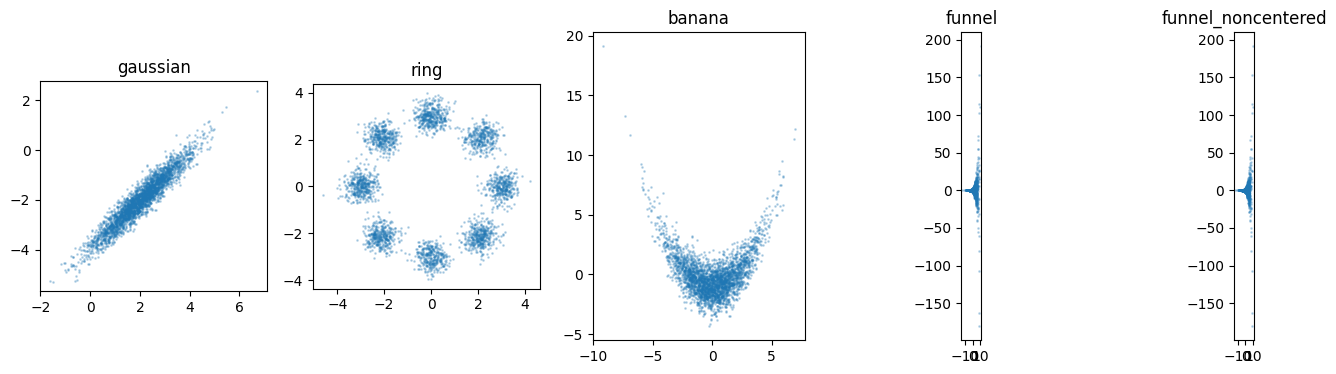

Reference draw moments retain Monte Carlo error; funnel extremes stay visible.


In [3]:
names=["gaussian","ring","banana","funnel","funnel_noncentered"]
fig,axes=plt.subplots(1,5,figsize=(17,4))
for ax,name in zip(axes,names):
 t=load_target(name);values=t.observable(t.reference(3000,np.random.default_rng(29)))
 ax.scatter(*values.T,s=1,alpha=.25);ax.set(title=name,aspect="equal")
plt.show()
print("Reference draw moments retain Monte Carlo error; funnel extremes stay visible.")

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.